In [5]:
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.optimizers import Adam, RMSprop, Adagrad
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.metrics import SparseCategoricalAccuracy

In [9]:
mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()


x_train = x_train / 255.0
x_test = x_test / 255.0


def create_model():

    model = Sequential([
        Flatten(input_shape=(28, 28)),

        Dense(256, activation='relu'),

        Dense(128, activation='relu'),

        Dense(64, activation='tanh'),

        Dense(10, activation='softmax')
    ])

    return model


In [10]:
def train_model(optimizer):

    model = create_model()

    model.compile(
        optimizer=optimizer,
        loss=SparseCategoricalCrossentropy(),
        metrics=[SparseCategoricalAccuracy()]
    )

    history = model.fit(
        x_train,
        y_train,
        epochs=10,
        validation_data=(x_test, y_test),
        verbose=1
    )

    test_loss, test_acc = model.evaluate(
        x_test,
        y_test,
        verbose=0
    )

    return model, history, test_loss, test_acc


print("\n================ ADAM ================\n")

adam_model, adam_history, adam_loss, adam_acc = train_model(
    Adam(learning_rate=0.001)
)



print("\n================ RMSPROP ================\n")

rmsprop_model, rmsprop_history, rmsprop_loss, rmsprop_acc = train_model(
    RMSprop(learning_rate=0.001)
)


print("\n================ ADAGRAD ================\n")

adagrad_model, adagrad_history, adagrad_loss, adagrad_acc = train_model(
    Adagrad(learning_rate=0.01)
)




print("\n========================================")
print("       FINAL TEST ACCURACY")
print("========================================")

print(f"Adam     Test Accuracy: {adam_acc:.4f}")
print(f"RMSprop  Test Accuracy: {rmsprop_acc:.4f}")
print(f"Adagrad  Test Accuracy: {adagrad_acc:.4f}")



================ ADAM ================

Epoch 1/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.2034 - sparse_categorical_accuracy: 0.9396 - val_loss: 0.1236 - val_sparse_categorical_accuracy: 0.9578
Epoch 2/10
1875/1875 [==============================] - 4s 2ms/step - loss: 0.0880 - sparse_categorical_accuracy: 0.9729 - val_loss: 0.0880 - val_sparse_categorical_accuracy: 0.9731
Epoch 3/10
1875/1875 [==============================] - 3s 2ms/step - loss: 0.0628 - sparse_categorical_accuracy: 0.9801 - val_loss: 0.0734 - val_sparse_categorical_accuracy: 0.9766
Epoch 4/10
1875/1875 [==============================] - 3s 2ms/step - loss: 0.0462 - sparse_categorical_accuracy: 0.9858 - val_loss: 0.0829 - val_sparse_categorical_accuracy: 0.9752
Epoch 5/10
1875/1875 [==============================] - 3s 2ms/step - loss: 0.0388 - sparse_categorical_accuracy: 0.9875 - val_loss: 0.0842 - val_sparse_categorical_accuracy: 0.9758
Epoch 6/10
1875/1875 [===========================

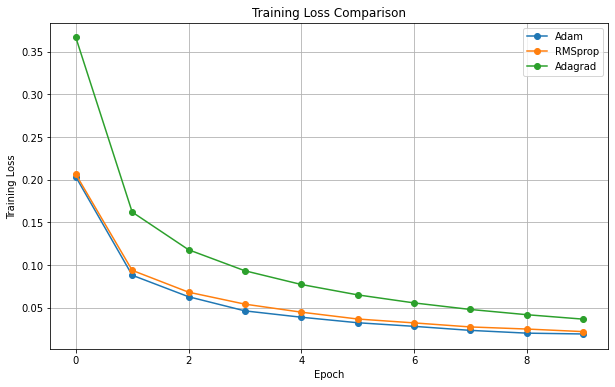

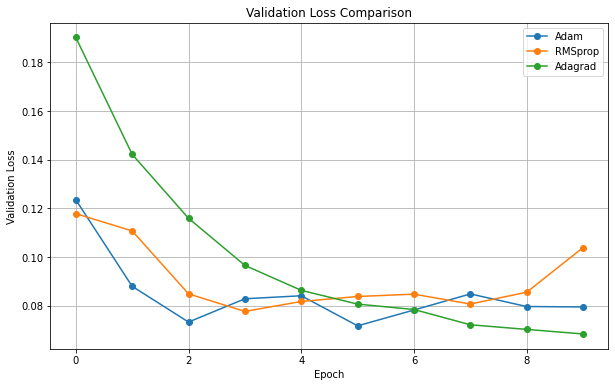

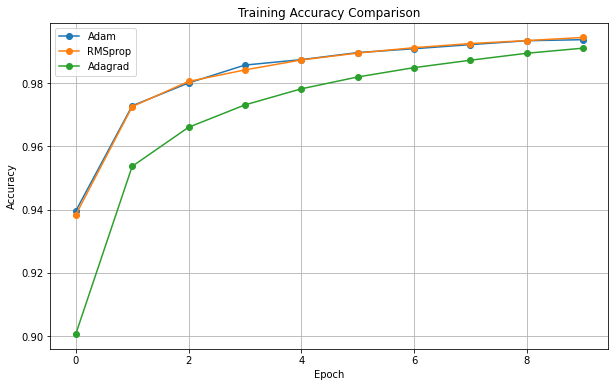

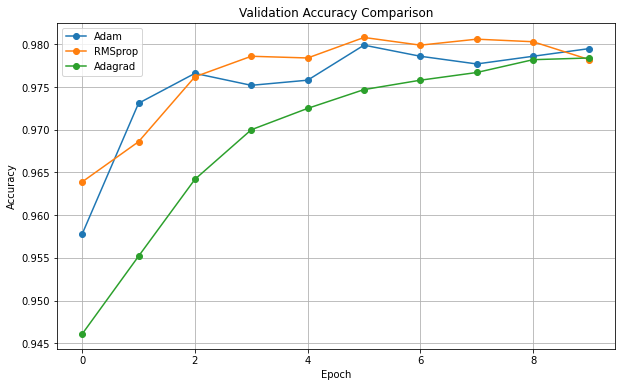

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    adam_history.history['loss'],
    label='Adam',
    marker='o'
)

plt.plot(
    rmsprop_history.history['loss'],
    label='RMSprop',
    marker='o'
)

plt.plot(
    adagrad_history.history['loss'],
    label='Adagrad',
    marker='o'
)

plt.title('Training Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Training Loss')
plt.legend()
plt.grid(True)

plt.show()


plt.figure(figsize=(10, 6))

plt.plot(
    adam_history.history['val_loss'],
    label='Adam',
    marker='o'
)

plt.plot(
    rmsprop_history.history['val_loss'],
    label='RMSprop',
    marker='o'
)

plt.plot(
    adagrad_history.history['val_loss'],
    label='Adagrad',
    marker='o'
)

plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

plt.figure(figsize=(10, 6))

plt.plot(
    adam_history.history['sparse_categorical_accuracy'],
    label='Adam',
    marker='o'
)

plt.plot(
    rmsprop_history.history['sparse_categorical_accuracy'],
    label='RMSprop',
    marker='o'
)

plt.plot(
    adagrad_history.history['sparse_categorical_accuracy'],
    label='Adagrad',
    marker='o'
)

plt.title('Training Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()



plt.figure(figsize=(10, 6))

plt.plot(
    adam_history.history['val_sparse_categorical_accuracy'],
    label='Adam',
    marker='o'
)

plt.plot(
    rmsprop_history.history['val_sparse_categorical_accuracy'],
    label='RMSprop',
    marker='o'
)

plt.plot(
    adagrad_history.history['val_sparse_categorical_accuracy'],
    label='Adagrad',
    marker='o'
)

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.show()